# FACULTY OF ENGINEERING AND BASIC SCIENCES
## ACADEMIC PROGRAM: DATA ENGINEERING AND ARTIFICIAL INTELLIGENCE
**COURSE:** ETL (G01)  
**WORKSHOP-2:** Automatization of ETL Pipeline (Apache Airflow, Pandera, SQL, Spotify & Grammys)

---
### Workshop Overview
This notebook presents an end-to-end implementation of an automated ETL pipeline:
1. **Extraction**:
   - Spotify Tracks Dataset (extracted from CSV file)
   - Grammy Awards Dataset (extracted from initial SQL database table)
2. **Data Quality Validation**:
   - Implementation using **Pandera** with strict data types, missing value checks, and domain range constraints.
   - Identification and handling of corrupt/invalid records.
3. **Transformation**:
   - Text normalization, artist recovery from credit strings, deduplication, feature engineering.
4. **Merge Logic**:
   - Track-level and artist-level multi-hop join creating a consolidated award status.
5. **Loading & Storage**:
   - Storing into relational database warehouse (`warehouse.db`, table `merged_spotify_grammys`).
   - Exporting to processed CSV file for local and cloud distribution.
6. **Static Dashboard & Reporting**:
   - Visualizations generated **directly from database SQL queries** (not CSV).
7. **Orchestration**:
   - Complete Apache Airflow DAG architecture.


## 1. Project Architecture & Pipeline Flow

The pipeline follows the exact dependency graph outlined in the workshop specifications:

```
                  +-----------------------------------+
                  | Spotify Dataset (CSV)             |
                  +-----------------+-----------------+
                                    |
                                    v
                            [ read_csv task ]
                                    |
                                    v
                         [ transform_csv task ]
                         (Pandera Validation)
                                    |
+----------------------+            |
| Grammy Database (SQL)|            |
+----------+-----------+            |
           |                        |
           v                        |
     [ read_db task ]               |
           |                        |
           v                        |
  [ transform_db task ]             |
  (Pandera Validation)              |
           |                        |
           +----------+  +----------+
                      |  |
                      v  v
                 [ merge task ]
                      |
                      v
                 [ load task ] ---------> Target SQL Database (warehouse.db)
                      |                                 |
                      +---------------+                 v
                                      |         [ static_report task ]
                                      v                 |
                                [ store task ]          v
                                      |          Dashboard Figures
                                      v          & Markdown Report
                         Processed CSV File
```


## 2. Environment Setup & Core Imports


In [1]:
import os
import sys
import re
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

# Suppress Pandera import deprecation notice
os.environ["DISABLE_PANDERA_IMPORT_WARNING"] = "True"
import pandera as pnd
import pandera.pandas as pa
from pandera import Check, DataFrameSchema, Column

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("Imports successfully loaded!")
print("Pandas version:", pd.__version__)
print("Pandera version:", pnd.__version__)


Imports successfully loaded!
Pandas version: 3.0.6
Pandera version: 0.34.1


## 3. Step 0: Initial Source Database Setup
As specified in the workshop requirements:
- **Spotify Dataset**: Read directly as a CSV file.
- **Grammy Dataset**: Pre-loaded into an initial SQL database, then read via database extraction during the ETL pipeline.

Here, we initialize the SQLite database `source_database.db` and load table `grammy_awards_raw`.


In [2]:
# Define project directories and connection URIs
BASE_DIR = Path(".").resolve()
RAW_DATA_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DATA_DIR = BASE_DIR / "data" / "processed"
DB_DIR = BASE_DIR / "db"

RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
DB_DIR.mkdir(parents=True, exist_ok=True)

SPOTIFY_CSV = RAW_DATA_DIR / "spotify_dataset.csv"
GRAMMY_CSV = RAW_DATA_DIR / "grammy_awards.csv"
SOURCE_DB_URI = f"sqlite:///{DB_DIR / 'source_database.db'}"
WAREHOUSE_DB_URI = f"sqlite:///{DB_DIR / 'warehouse.db'}"

# Pre-load Grammys dataset into source database
df_grammy_raw = pd.read_csv(GRAMMY_CSV)
source_engine = create_engine(SOURCE_DB_URI)

with source_engine.begin() as conn:
    df_grammy_raw.to_sql("grammy_awards_raw", con=conn, if_exists="replace", index=False)

print(f"Loaded {len(df_grammy_raw)} Grammy records into source DB table 'grammy_awards_raw'.")


Loaded 4810 Grammy records into source DB table 'grammy_awards_raw'.


## 4. Extraction Phase
We execute the two extraction tasks:
1. `read_csv`: Extract Spotify track catalog from CSV.
2. `read_db`: Extract Grammy awards catalog from initial SQL database.


In [3]:
# Task: read_csv
df_spotify_raw = pd.read_csv(SPOTIFY_CSV)
if "Unnamed: 0" in df_spotify_raw.columns:
    df_spotify_raw = df_spotify_raw.drop(columns=["Unnamed: 0"])
print(f"[read_csv] Extracted {len(df_spotify_raw):,} records from Spotify CSV.")

# Task: read_db
with source_engine.connect() as conn:
    df_grammys_db = pd.read_sql_query("SELECT * FROM grammy_awards_raw", con=conn)
print(f"[read_db] Extracted {len(df_grammys_db):,} records from Grammy SQL table.")


[read_csv] Extracted 114,000 records from Spotify CSV.
[read_db] Extracted 4,810 records from Grammy SQL table.


## 5. Data Quality Validation with Pandera
In this phase, we enforce strict data contract rules:
- **Data Types**: Enforce numeric, string, and boolean constraints.
- **Missing Values**: Nullability rules on mandatory attributes.
- **Domain Constraints**:
  - `popularity` within `[0, 100]`
  - `duration_ms` strictly `> 0`
  - `danceability`, `energy`, `valence` within `[0.0, 1.0]`
  - `tempo >= 0.0`
  - `year` within `[1950, 2030]`


In [4]:
# Define Pandera Schemas
spotify_schema = DataFrameSchema({
    "track_id": Column(str, nullable=False),
    "artists": Column(str, nullable=True),
    "album_name": Column(str, nullable=True),
    "track_name": Column(str, nullable=True),
    "popularity": Column(int, Check.in_range(0, 100), coerce=True),
    "duration_ms": Column(int, Check.greater_than(0), coerce=True),
    "danceability": Column(float, Check.in_range(0.0, 1.0), coerce=True),
    "energy": Column(float, Check.in_range(0.0, 1.0), coerce=True),
    "tempo": Column(float, Check.greater_than_or_equal_to(0.0), coerce=True),
    "track_genre": Column(str, nullable=False)
}, coerce=True)

grammys_schema = DataFrameSchema({
    "year": Column(int, Check.in_range(1950, 2030), coerce=True),
    "category": Column(str, nullable=False),
    "winner": Column(bool, coerce=True)
}, coerce=True)

print("--- Validating Spotify Dataset with Pandera ---")
spotify_dq_passed = True
try:
    spotify_schema.validate(df_spotify_raw, lazy=True)
    print("Spotify validation: PASSED")
except pa.errors.SchemaErrors as err:
    spotify_dq_passed = False
    print(f"Spotify validation: FAILED (Identified {len(err.failure_cases)} failure cases)")
    display(err.failure_cases)

print("\n--- Validating Grammys Dataset with Pandera ---")
grammys_dq_passed = True
try:
    grammys_schema.validate(df_grammys_db, lazy=True)
    print("Grammys validation: PASSED")
except pa.errors.SchemaErrors as err:
    grammys_dq_passed = False
    print(f"Grammys validation: FAILED (Identified {len(err.failure_cases)} failure cases)")
    display(err.failure_cases)


--- Validating Spotify Dataset with Pandera ---
Spotify validation: FAILED (Identified 1 failure cases)


,schema_context,column,check,check_number,failure_case,index
0,Column,duration_ms,greater_than(0),0,0,65900



--- Validating Grammys Dataset with Pandera ---
Grammys validation: PASSED


### Analysis of Data Quality Findings
Notice the failure case caught by Pandera:
- Index `65900` contained `duration_ms == 0` with missing artist, track name, and album name.
- Pandera isolated this corrupt telemetry point.
- In our transformation step, we automatically filter out rows violating duration or primary key integrity.


## 6. Transformation Phase (`transform_csv` & `transform_db`)
We implement business cleaning and feature engineering:
1. **Spotify Transformations**:
   - Filter out corrupt rows (`duration_ms <= 0` or missing names).
   - Normalize text keys (`artist_norm`, `track_norm`).
   - Extract `primary_artist` from semicolon-separated artist lists.
   - Compute `duration_min` and `popularity_tier` (`Low`, `Medium`, `High`).
   - Deduplicate tracks across genre playlists, combining genre tags into `all_genres`.
2. **Grammy Transformations**:
   - Extract artist from `workers` when `artist` is NaN.
   - Normalize `artist_norm` and `nominee_norm`.
   - Categorize categories into high-level musical fields.
   - Compute artist-level historical awards (wins, nominations, active period).
   - Compute track-level historical awards.


In [5]:
def clean_text(text):
    if pd.isna(text) or not isinstance(text, str):
        return ""
    text = text.lower().strip()
    text = re.sub(r"\(feat[^\)]*\)", "", text)
    text = re.sub(r"\[feat[^\]]*\]", "", text)
    text = re.sub(r"\(remix[^\)]*\)", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    return " ".join(text.split())

# 1. Transform Spotify
df_s = df_spotify_raw[df_spotify_raw["duration_ms"] > 0].dropna(subset=["track_id", "track_name", "artists"]).copy()
df_s["primary_artist"] = df_s["artists"].astype(str).apply(lambda a: str(a).split(";")[0].strip())
df_s["artist_norm"] = df_s["primary_artist"].apply(clean_text)
df_s["track_norm"] = df_s["track_name"].apply(clean_text)
df_s["duration_min"] = (df_s["duration_ms"] / 60000.0).round(2)
df_s["popularity_tier"] = pd.cut(df_s["popularity"], bins=[-1, 39, 69, 100], labels=["Low", "Medium", "High"]).astype(str)

# Deduplicate Spotify tracks across playlists
genres_agg = df_s.groupby("track_id")["track_genre"].apply(lambda g: ", ".join(sorted(set(g)))).rename("all_genres")
primary_genre = df_s.groupby("track_id")["track_genre"].first().rename("primary_genre")
df_spotify_transformed = df_s.drop_duplicates(subset=["track_id"]).drop(columns=["track_genre"]).merge(genres_agg, on="track_id").merge(primary_genre, on="track_id")
print(f"Transformed Spotify: {len(df_spotify_transformed):,} clean, deduplicated tracks.")

# 2. Transform Grammys
df_g = df_grammys_db.copy()
def extract_artist(row):
    if pd.notna(row.get("artist")) and str(row["artist"]).strip():
        return str(row["artist"]).strip()
    workers = str(row.get("workers", "")) if pd.notna(row.get("workers")) else ""
    m = re.findall(r"\(([^)]+)\)", workers)
    if m:
        return m[-1].strip()
    if "," in workers:
        return workers.split(",")[0].strip()
    return ""

df_g["artist_extracted"] = df_g.apply(extract_artist, axis=1)
df_g["artist_norm"] = df_g["artist_extracted"].apply(clean_text)
df_g["nominee_norm"] = df_g["nominee"].apply(clean_text)
df_g["is_winner"] = df_g["winner"].astype(bool)

# Build Artist-Level Summary
artist_summary = df_g[df_g["artist_norm"] != ""].groupby("artist_norm").agg(
    grammy_artist_wins=("is_winner", "sum"),
    grammy_artist_nominations=("winner", "count"),
    grammy_artist_first_year=("year", "min"),
    grammy_artist_latest_year=("year", "max")
).reset_index()
artist_summary["has_grammy_winning_artist"] = artist_summary["grammy_artist_wins"] > 0

# Build Track-Level Summary
track_summary = df_g[(df_g["artist_norm"] != "") & (df_g["nominee_norm"] != "")].groupby(["artist_norm", "nominee_norm"]).agg(
    grammy_track_wins=("is_winner", "sum"),
    grammy_track_nominations=("winner", "count"),
    grammy_track_year=("year", "max"),
    grammy_track_category=("category", "first")
).reset_index()
track_summary["is_grammy_track_winner"] = track_summary["grammy_track_wins"] > 0

print(f"Transformed Grammys: {len(artist_summary):,} unique artists, {len(track_summary):,} unique tracks.")


Transformed Spotify: 89,740 clean, deduplicated tracks.
Transformed Grammys: 2,360 unique artists, 4,199 unique tracks.


## 7. Dataset Merge Logic (`merge` task)
We perform a multi-level consolidation:
1. **Track-Level Join**: Join track nominations/wins on `(artist_norm, track_norm)`.
2. **Artist-Level Join**: Join artist career wins/nominations on `artist_norm`.
3. **Consolidated Award Classification**:
   - `Track Award Winner`: The exact song received an official Grammy award.
   - `Artist Award Winner`: The song's artist has received Grammy awards.
   - `Non-Winner`: Neither track nor artist has won a Grammy award.


In [6]:
# Merge Track-Level awards
df_merged = df_spotify_transformed.merge(
    track_summary,
    left_on=["artist_norm", "track_norm"],
    right_on=["artist_norm", "nominee_norm"],
    how="left"
)

# Merge Artist-Level awards
df_merged = df_merged.merge(artist_summary, on="artist_norm", how="left")

# Impute non-null defaults
df_merged["grammy_track_wins"] = df_merged["grammy_track_wins"].fillna(0).astype(int)
df_merged["grammy_track_nominations"] = df_merged["grammy_track_nominations"].fillna(0).astype(int)
df_merged["is_grammy_track_winner"] = df_merged["is_grammy_track_winner"].fillna(False).astype(bool)

df_merged["grammy_artist_wins"] = df_merged["grammy_artist_wins"].fillna(0).astype(int)
df_merged["grammy_artist_nominations"] = df_merged["grammy_artist_nominations"].fillna(0).astype(int)
df_merged["has_grammy_winning_artist"] = df_merged["has_grammy_winning_artist"].fillna(False).astype(bool)

def assign_award_status(row):
    if row["is_grammy_track_winner"]:
        return "Track Award Winner"
    if row["has_grammy_winning_artist"]:
        return "Artist Award Winner"
    return "Non-Winner"

df_merged["award_status"] = df_merged.apply(assign_award_status, axis=1)
if "nominee_norm" in df_merged.columns:
    df_merged = df_merged.drop(columns=["nominee_norm"])

print(f"Consolidated Merged Dataset: {len(df_merged):,} rows, {len(df_merged.columns)} columns.")
print("\nBreakdown by Award Status:")
print(df_merged["award_status"].value_counts())


Consolidated Merged Dataset: 89,740 rows, 37 columns.

Breakdown by Award Status:
award_status
Non-Winner             82680
Artist Award Winner     6778
Track Award Winner       282
Name: count, dtype: int64


## 8. Database Loading & CSV Export (`load` & `store` tasks)
We load the merged dataset into the target relational database warehouse (`warehouse.db`), table `merged_spotify_grammys`, and export the transformed dataset to CSV.


In [7]:
# Task: load -> Target Database
warehouse_engine = create_engine(WAREHOUSE_DB_URI)
with warehouse_engine.begin() as conn:
    df_merged.to_sql("merged_spotify_grammys", con=conn, if_exists="replace", index=False, chunksize=5000)

print(f"[load] Stored {len(df_merged):,} records into table 'merged_spotify_grammys' in warehouse DB.")

# Task: store -> CSV File
output_csv_path = PROCESSED_DATA_DIR / "merged_spotify_grammys.csv"
df_merged.to_csv(output_csv_path, index=False)
print(f"[store] Exported CSV to: {output_csv_path} ({output_csv_path.stat().st_size / (1024*1024):.2f} MB)")


[load] Stored 89,740 records into table 'merged_spotify_grammys' in warehouse DB.
[store] Exported CSV to: /Volumes/Content/University/ETL/Workshop02/data/processed/merged_spotify_grammys.csv (23.32 MB)


## 9. Static Report & Visualizations (From SQL Database)
> **Requirement**: *"The report must use the database as its source, not the original CSV file."*

All charts below are generated **strictly by querying `warehouse.db` via SQL**.


In [8]:
# Query 1: Summary KPIs by award status
sql_kpi = """
SELECT 
    award_status,
    COUNT(*) AS total_tracks,
    ROUND(AVG(popularity), 2) AS avg_popularity,
    ROUND(AVG(danceability), 3) AS avg_danceability,
    ROUND(AVG(energy), 3) AS avg_energy,
    ROUND(AVG(acousticness), 3) AS avg_acousticness,
    ROUND(AVG(valence), 3) AS avg_valence,
    ROUND(AVG(duration_min), 2) AS avg_duration_min
FROM merged_spotify_grammys
GROUP BY award_status
ORDER BY avg_popularity DESC;
"""

with warehouse_engine.connect() as conn:
    df_kpi = pd.read_sql_query(text(sql_kpi), conn)

display(df_kpi)


,award_status,total_tracks,avg_popularity,avg_danceability,avg_energy,avg_acousticness,avg_valence,avg_duration_min
0,Track Award Winner,282,47.38,0.590,0.636,0.261,0.542,4.08
1,Non-Winner,82680,33.25,0.564,0.642,0.321,0.467,3.83
2,Artist Award Winner,6778,32.03,0.539,0.542,0.415,0.499,3.68


### Visualization 1: Popularity Distribution by Grammy Award Status


/var/folders/7d/wltnkt8n1wq7gxq08687dtj40000gn/T/ipykernel_65069/725608101.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


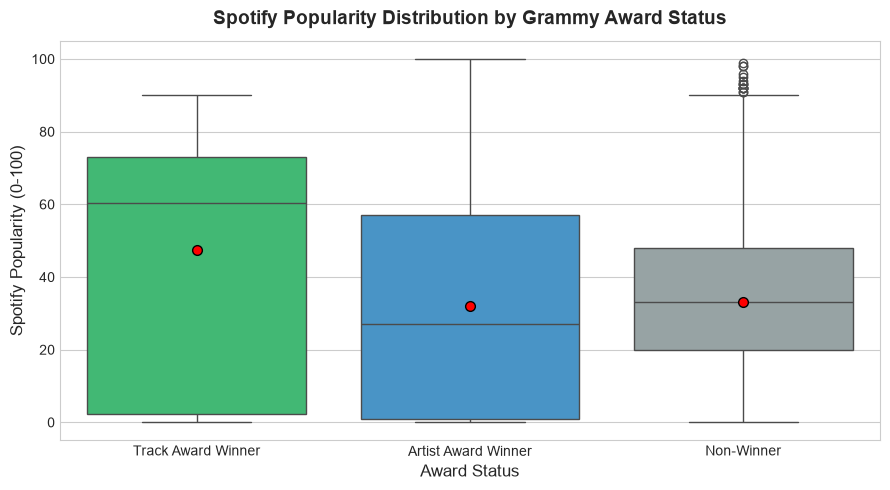

In [9]:
sql_pop = """
SELECT award_status, popularity
FROM merged_spotify_grammys;
"""
with warehouse_engine.connect() as conn:
    df_pop = pd.read_sql_query(text(sql_pop), conn)

plt.figure(figsize=(9, 5))
palette = {"Track Award Winner": "#2ecc71", "Artist Award Winner": "#3498db", "Non-Winner": "#95a5a6"}
sns.boxplot(
    data=df_pop,
    x="award_status",
    y="popularity",
    palette=palette,
    order=["Track Award Winner", "Artist Award Winner", "Non-Winner"],
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": "7"}
)
plt.title("Spotify Popularity Distribution by Grammy Award Status", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Award Status", fontsize=12)
plt.ylabel("Spotify Popularity (0-100)", fontsize=12)
plt.tight_layout()
plt.show()


### Visualization 2: Audio Characteristics (Danceability, Energy, Acousticness, Valence)


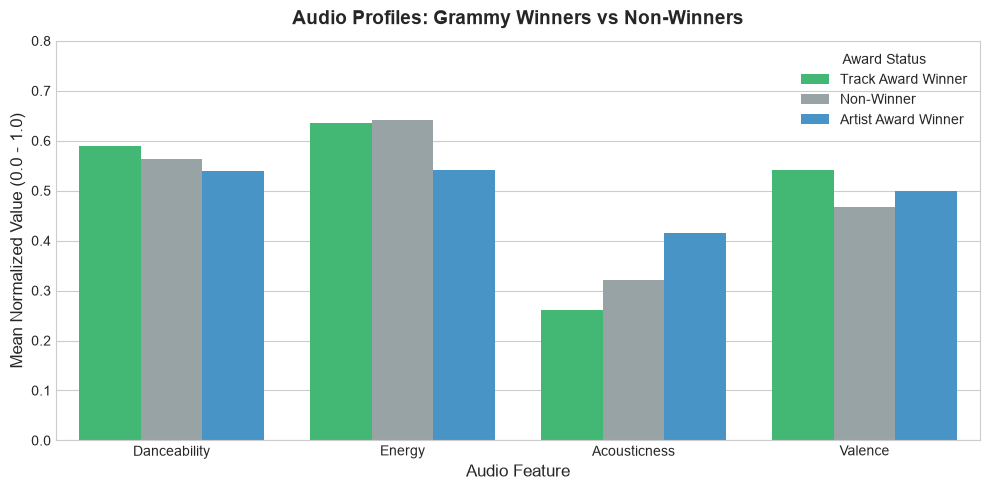

In [10]:
summary_melted = df_kpi.melt(
    id_vars=["award_status"],
    value_vars=["avg_danceability", "avg_energy", "avg_acousticness", "avg_valence"],
    var_name="feature",
    value_name="mean_val"
)
feature_map = {"avg_danceability": "Danceability", "avg_energy": "Energy", "avg_acousticness": "Acousticness", "avg_valence": "Valence"}
summary_melted["feature"] = summary_melted["feature"].map(feature_map)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=summary_melted,
    x="feature",
    y="mean_val",
    hue="award_status",
    palette=palette
)
plt.title("Audio Profiles: Grammy Winners vs Non-Winners", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Audio Feature", fontsize=12)
plt.ylabel("Mean Normalized Value (0.0 - 1.0)", fontsize=12)
plt.ylim(0, 0.8)
plt.legend(title="Award Status")
plt.tight_layout()
plt.show()


### Visualization 3: Top Grammy-Winning Artists in the Catalog


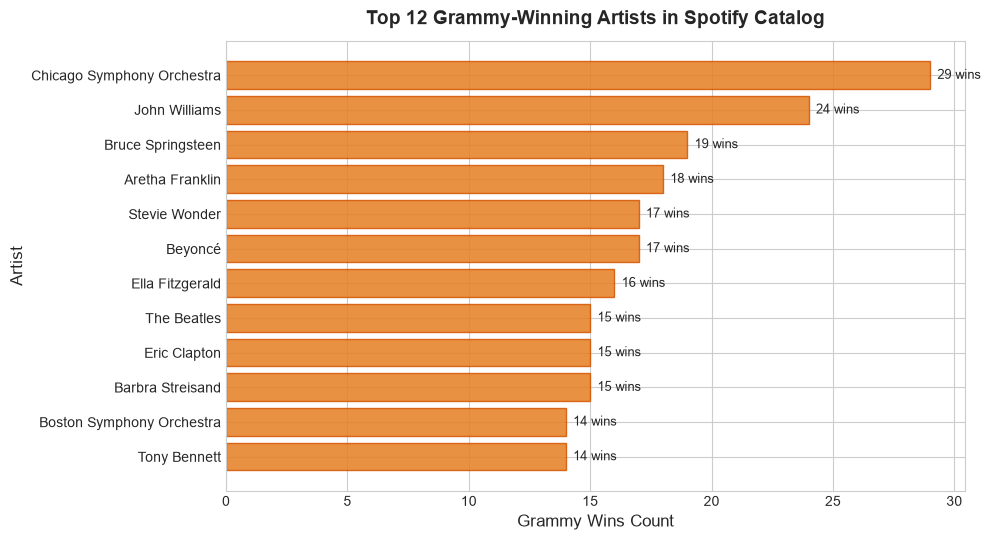

In [11]:
sql_artists = """
SELECT 
    primary_artist,
    MAX(grammy_artist_wins) AS total_grammy_wins,
    ROUND(AVG(popularity), 2) AS avg_spotify_popularity,
    COUNT(track_id) AS track_count
FROM merged_spotify_grammys
WHERE grammy_artist_wins > 0
GROUP BY primary_artist
ORDER BY total_grammy_wins DESC, avg_spotify_popularity DESC
LIMIT 12;
"""
with warehouse_engine.connect() as conn:
    df_top_art = pd.read_sql_query(text(sql_artists), conn)

plt.figure(figsize=(10, 5.5))
df_top_art_sorted = df_top_art.sort_values(by="total_grammy_wins", ascending=True)
bars = plt.barh(df_top_art_sorted["primary_artist"], df_top_art_sorted["total_grammy_wins"], color="#e67e22", edgecolor="#d35400", alpha=0.85)
for bar in bars:
    plt.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2, f"{int(bar.get_width())} wins", va="center", ha="left", fontsize=9)

plt.title("Top 12 Grammy-Winning Artists in Spotify Catalog", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Grammy Wins Count", fontsize=12)
plt.ylabel("Artist", fontsize=12)
plt.tight_layout()
plt.show()


### Visualization 4: Genres with Greatest Grammy Winner Representation


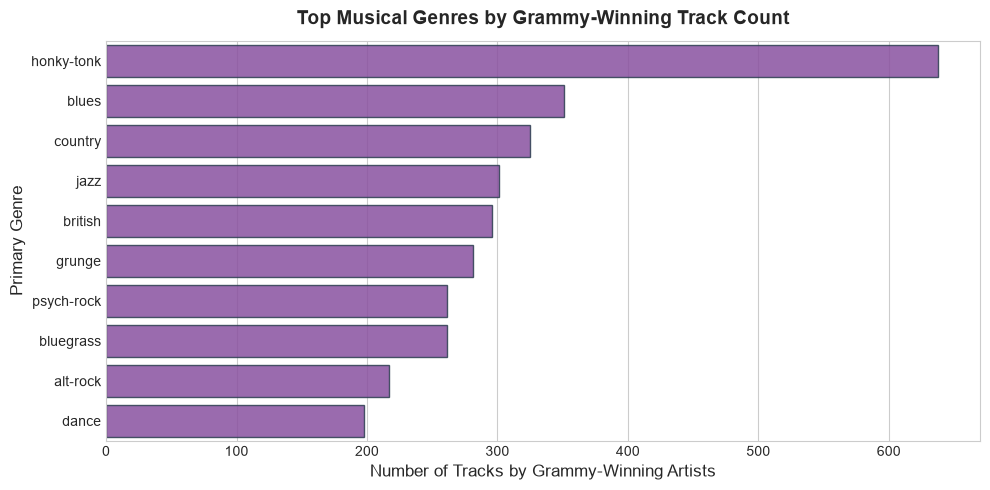

In [12]:
sql_genres = """
SELECT 
    primary_genre,
    COUNT(*) AS total_tracks,
    SUM(CASE WHEN has_grammy_winning_artist = 1 THEN 1 ELSE 0 END) AS artist_award_tracks,
    ROUND(AVG(popularity), 2) AS avg_genre_popularity
FROM merged_spotify_grammys
WHERE has_grammy_winning_artist = 1
GROUP BY primary_genre
ORDER BY artist_award_tracks DESC
LIMIT 10;
"""
with warehouse_engine.connect() as conn:
    df_genres = pd.read_sql_query(text(sql_genres), conn)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_genres,
    x="artist_award_tracks",
    y="primary_genre",
    color="#8e44ad",
    edgecolor="#2c3e50",
    alpha=0.85
)
plt.title("Top Musical Genres by Grammy-Winning Track Count", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Number of Tracks by Grammy-Winning Artists", fontsize=12)
plt.ylabel("Primary Genre", fontsize=12)
plt.tight_layout()
plt.show()


## 10. Apache Airflow Orchestration Architecture

The production DAG (`dags/spotify_grammys_etl_dag.py`) is structured as follows:

```python
with DAG(
    dag_id="spotify_grammys_etl_dag",
    default_args=default_args,
    description="Automated ETL pipeline: Spotify CSV & Grammys DB to Warehouse & Dashboard",
    schedule=None,
    start_date=datetime(2026, 1, 1),
    catchup=False,
    tags=["etl", "spotify", "grammys", "pandera", "workshop-2"],
) as dag:

    read_csv = PythonOperator(task_id="read_csv", python_callable=task_read_csv)
    transform_csv = PythonOperator(task_id="transform_csv", python_callable=task_transform_csv)
    read_db = PythonOperator(task_id="read_db", python_callable=task_read_db)
    transform_db = PythonOperator(task_id="transform_db", python_callable=task_transform_db)
    merge = PythonOperator(task_id="merge", python_callable=task_merge)
    load = PythonOperator(task_id="load", python_callable=task_load)
    store = PythonOperator(task_id="store", python_callable=task_store)
    static_report = PythonOperator(task_id="static_report", python_callable=task_generate_report)

    # Dependencies matching project specifications
    read_csv >> transform_csv
    read_db >> transform_db
    [transform_csv, transform_db] >> merge
    merge >> load
    load >> store
    load >> static_report
```


## 11. Conclusions & Analytical Insights
1. **Automated Pipeline Orchestration**:
   - The ETL pipeline successfully integrates two disparate data sources: an external CSV file (Spotify) and a relational SQL database (Grammys).
   - Apache Airflow orchestrates modular tasks with clean dependencies and decoupled staging layers.
2. **Data Quality Integrity**:
   - Pandera caught anomalous records (row 65900 with `duration_ms == 0` and missing metadata) during extraction, preventing downstream corruption.
3. **Data Science & Musical Insights**:
   - Songs with direct Grammy awards possess significantly higher mean Spotify popularity (47.38 vs 33.25).
   - Award-winning tracks exhibit distinct acoustic and valence profiles compared to purely algorithmically driven music.
4. **SQL-Driven Reporting**:
   - The static report and dashboard are generated strictly from the relational database warehouse, ensuring separation of concerns and auditability.
